# Data-poisoning a **logistic-regression** victim

The victim performs online mini-batch SGD on the binary cross-entropy loss

$$\ell_i = -\big[y_i\log\sigma(\langle\theta,x_i\rangle) + (1-y_i)\log(1-\sigma(\langle\theta,x_i\rangle))\big],
\qquad \nabla\ell_i = \big(\sigma(\langle\theta,x_i\rangle)-y_i\big)\,x_i$$

with labels $y_i\sim\mathrm{Bernoulli}(\sigma(\langle\theta^\star,x_i\rangle))$, flipped with
probability `noise`.

**Why the method transfers unchanged.** Both tasks have gradient `resid_i * x_i`; only the
residual differs (`<θ,x>-y` vs `σ(<θ,x>)-y`). One SGD step is therefore still

$$\theta_{t+1} = \theta_t - \tfrac{\eta}{m}\sum_i a_i\nabla\ell_i = \theta_t + \sum_i a_i\varphi_i$$

so the transition stays **action-linear** and the whole per-point decomposition
($\alpha$, $B$, all three selection tiers) applies verbatim. Only `Victim.residual`
changes.

**One thing does change: scale.** The logistic residual is bounded in $(-1,1)$ while the
least-squares residual has std $\approx\!2.2$, so $|\varphi|$ is ~5× smaller. Both `eta` and
`c_edit` must be retuned or the attack barely registers — see the sweep in §5.

In [1]:
import os, sys
from pathlib import Path
_ROOT = Path.cwd()
if _ROOT.name == "notebooks":        # run from notebooks/: work from the repo root
    _ROOT = _ROOT.parent; os.chdir(_ROOT)
sys.path.insert(0, str(_ROOT / "src"))

import time
from dataclasses import replace

import numpy as np
import torch
import matplotlib.pyplot as plt
%matplotlib inline

from config import EnvConfig, MethodConfig, TIER_NAME
from env import Environment, is_feasible
from fvi import train_fvi, evaluate, rollout
from agents import NullAgent, RandomAgent, GreedyAgent, MethodAgent
from decomposition import scores_and_interaction

# NB: do not `import viz` / `import diagnostics` -- they call matplotlib.use("Agg")
# at import time, which disables inline plots.
plt.rcParams["figure.dpi"] = 110
plt.rcParams.update({
    "savefig.dpi": 300,
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Helvetica", "Arial"],
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "xtick.labelsize": 9.5,
    "ytick.labelsize": 9.5,
    "legend.fontsize": 9.5,
    "legend.frameon": False,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "0.85",
    "grid.linewidth": 0.6,
    "grid.alpha": 0.6,
})
print("torch", torch.__version__)

torch 2.11.0+cu128


## Configuration

Retuned for logistic: `eta=1.0` (vs 0.2 for regression) and `c_edit=0.02`, from the sweep
in §5. Runtime ≈ 1 min for the main experiment.

In [2]:
ECFG = EnvConfig(d=5, m=10, T=10, eta=1.0, noise=0.1, task="logistic")
CFG  = MethodConfig(select_mode="greedy", c_edit=0.02, weight_decay=1e-3,
                    K_iters=20)
EVAL_EPISODES, EVAL_SEED = 200, 999

INCLUDE_MODEL_FREE = True   # train BDQ / TRPO too (adds several minutes)
TRPO_ITERS = 50             # TRPO converges later than the others -- see note

torch.manual_seed(0)
env = Environment(ECFG, CFG)
print(f"task={ECFG.task}  d={env.d}  m={env.m}  T={env.T}  eta={ECFG.eta}  c_edit={CFG.c_edit}")
z0 = env.stream.sample_batch(8, torch.Generator().manual_seed(0))
print("sample labels (binary):", z0[1].tolist())

task=logistic  d=5  m=10  T=10  eta=1.0  c_edit=0.02
sample labels (binary): [0.0, 1.0, 1.0, 1.0, 1.0, 0.0, 1.0, 0.0]


In [3]:
def compare(env, cfg, V, seeds_rng=1, tiers=("greedy",)):
    """Evaluate every policy on the SAME held-out episodes."""
    agents = {
        "null":   NullAgent(),
        "random": RandomAgent(torch.Generator().manual_seed(2), cfg.balance, cfg.B, cfg.L),
        "greedy": GreedyAgent(env.victim, env.theta_target, cfg, mode="greedy"),
    }
    for t in tiers:
        agents[TIER_NAME[t]] = MethodAgent(
            V, env.victim, env.theta_target, replace(cfg, select_mode=t),
            torch.Generator().manual_seed(seeds_rng))
    out = {}
    for n, ag in agents.items():
        c = evaluate(env, ag, torch.Generator().manual_seed(EVAL_SEED), EVAL_EPISODES)
        e, g = behaviour(env, ag)
        out[n] = {"cost": c, "edits": e, "gap": g, "agent": ag}
    return out


def behaviour(env, agent, n_episodes=60):
    """Mean edits/step and mean ||theta_t - theta_target||; also asserts feasibility."""
    rng = torch.Generator().manual_seed(EVAL_SEED)
    edits = gap = 0.0
    steps = 0
    for _ in range(n_episodes):
        theta = env.theta_0.clone()
        for t in range(env.T):
            z = env.stream.sample_batch(env.m, rng)
            a = agent.act(theta, z, t)
            assert is_feasible(a, CFG.balance, CFG.B, CFG.L), "infeasible action!"
            edits += float(np.abs(a.numpy() - 1).sum())
            theta = env.victim.update(theta, z, a).detach()
            gap += float((theta - env.theta_target).norm())
            steps += 1
    return edits / steps, gap / steps


def bar_report(res, title):
    names = list(res)
    colors = {"null": "#5b5b5b", "random": "#008300", "greedy": "#eb6834",
              "TRPO": "#4a3aa7", "BDQ": "#e34948", "first-order": "#2a78d6"}
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.2))
    a1.bar(range(len(names)), [res[n]["cost"] for n in names],
           color=[colors.get(n, "C7") for n in names])
    a1.axhline(res["null"]["cost"], color=colors["null"], ls="--", lw=1)
    a1.set_xticks(range(len(names))); a1.set_xticklabels(names, rotation=15, fontsize=8)
    a1.set_ylabel("mean episode cost"); a1.set_title(title)
    a2.bar(range(len(names)), [res[n]["edits"] for n in names],
           color=[colors.get(n, "C7") for n in names])
    a2.set_xticks(range(len(names))); a2.set_xticklabels(names, rotation=15, fontsize=8)
    a2.set_ylabel("points edited per step"); a2.set_title("Editing aggressiveness")
    plt.tight_layout(); plt.show()
    nul = res["null"]["cost"]
    for n in names:
        print(f"  {n:18} cost={res[n]['cost']:9.3f}  ({res[n]['cost']/nul:5.3f} x null)"
              f"  edits={res[n]['edits']:5.2f}  gap={res[n]['gap']:7.3f}")

## 1. Train and compare

All policies are scored on the **same** held-out episodes. The model-free
baselines (TRPO, BDQ) see the identical environment, constraints and
feature set, and every action is asserted feasible.

> **On TRPO's budget.** TRPO trades sample efficiency for stability -- its hard KL
> bound guarantees it cannot collapse, but each step is small, so it converges
> later. We give it `TRPO_ITERS = 50` against `K_iters = 20` for the others. That
> is **generous to the baseline**, not to us; at matched iterations TRPO is still
> near null and the comparison would flatter our method.

trained in 17s
  TRPO  (K=50) cost=    2.741  edits= 4.23  [74s]
  BDQ   (K=20) cost=    2.795  edits= 3.38  [177s]


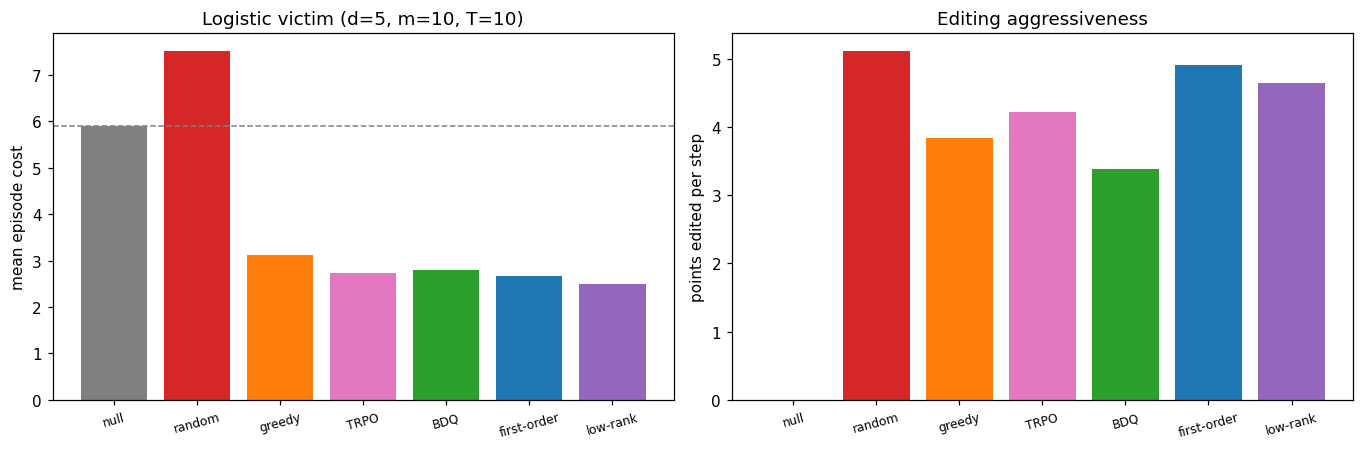

  null               cost=    5.899  (1.000 x null)  edits= 0.00  gap=  1.079
  random             cost=    7.524  (1.276 x null)  edits= 5.12  gap=  1.145
  greedy             cost=    3.114  (0.528 x null)  edits= 3.85  gap=  0.673
  TRPO               cost=    2.741  (0.465 x null)  edits= 4.23  gap=  0.589
  BDQ                cost=    2.795  (0.474 x null)  edits= 3.38  gap=  0.618
  first-order        cost=    2.661  (0.451 x null)  edits= 4.91  gap=  0.559
  low-rank           cost=    2.498  (0.423 x null)  edits= 4.64  gap=  0.537


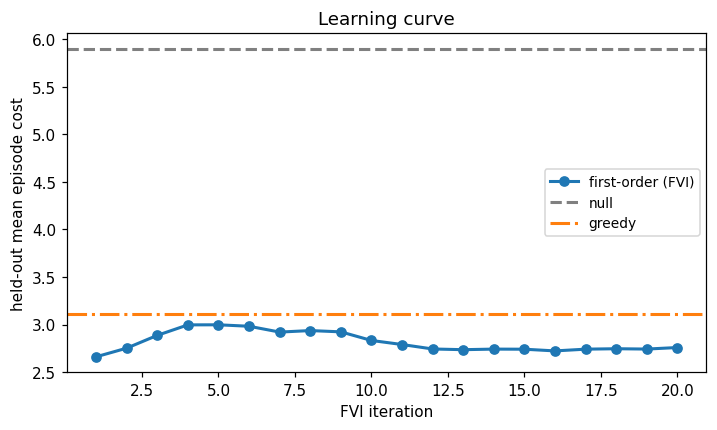

In [4]:
t0 = time.perf_counter()
V, hist = train_fvi(env, CFG, seed=0, verbose=False, return_history=True,
                    best_checkpoint=True, eval_episodes=EVAL_EPISODES, eval_seed=EVAL_SEED)
print(f"trained in {time.perf_counter()-t0:.0f}s")

# --- model-free RL baselines, trained on the SAME env / eval episodes ---
if INCLUDE_MODEL_FREE:
    from bdq import train_bdq, BDQAgent
    from trpo import train_trpo, TRPOAgent

    res_mf = {}
    for name, tr, Ag, K in [
                            ("TRPO", train_trpo, TRPOAgent, TRPO_ITERS),
                            ("BDQ",  train_bdq,  BDQAgent,  CFG.K_iters)]:
        cfg_k = replace(CFG, K_iters=K)
        torch.manual_seed(0)
        t0 = time.perf_counter()
        net = tr(env, cfg_k, seed=0, verbose=False, best_checkpoint=True,
                 eval_episodes=EVAL_EPISODES, eval_seed=EVAL_SEED)
        ag = Ag(net, env, cfg_k, torch.Generator().manual_seed(1))
        c = evaluate(env, ag, torch.Generator().manual_seed(EVAL_SEED), EVAL_EPISODES)
        e, g = behaviour(env, ag)
        res_mf[name] = {"cost": c, "edits": e, "gap": g, "agent": ag}
        print(f"  {name:5} (K={K:2d}) cost={c:9.3f}  edits={e:5.2f}  "
              f"[{time.perf_counter()-t0:.0f}s]", flush=True)
else:
    res_mf = {}

res = compare(env, CFG, V)
res.update(res_mf)
ORDER = ["null", "random", "greedy", "TRPO", "BDQ", "first-order"]
res = {k: res[k] for k in ORDER if k in res}
bar_report(res, f"Logistic victim (d={env.d}, m={env.m}, T={env.T})")

plt.figure(figsize=(7.5, 4))
plt.plot(range(1, len(hist) + 1), hist, "o-", color="#2a78d6", lw=2, label=f"{TIER_NAME[CFG.select_mode]} (FVI)")
plt.axhline(res["null"]["cost"], color="#5b5b5b", ls="--", lw=2, label="null")
plt.axhline(res["greedy"]["cost"], color="#eb6834", ls="-.", lw=2, label="greedy")
plt.xlabel("FVI iteration"); plt.ylabel("held-out mean episode cost")
plt.title("Learning curve"); plt.legend(fontsize=9); plt.show()

## 2. What the attack does to the classifier

Cost is an abstraction; for a classifier the interpretable quantities are **accuracy** and
the **decision boundary**. Accuracy is measured on a large clean test batch drawn from the
true model.

/tmp/ipykernel_51220/2309139252.py:29: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=9); plt.show()


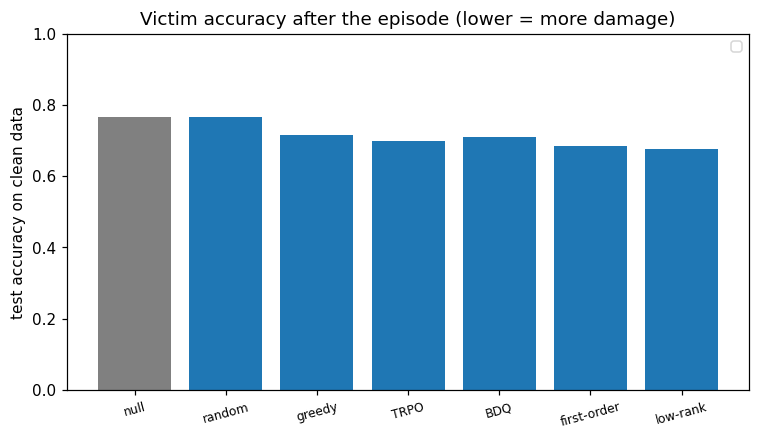

  null               accuracy = 0.767
  random             accuracy = 0.768
  greedy             accuracy = 0.715
  TRPO               accuracy = 0.699
  BDQ                accuracy = 0.710
  first-order        accuracy = 0.686
  low-rank           accuracy = 0.676


In [7]:
def accuracy(env, theta, n=4000, seed=7):
    rng = torch.Generator().manual_seed(seed)
    x, y = env.stream.sample_batch(n, rng)
    return float(((torch.sigmoid(x @ theta) > 0.5).float() == y).float().mean())

def final_theta(env, agent, seed=EVAL_SEED, n_ep=40):
    rng = torch.Generator().manual_seed(seed)
    ths = []
    for _ in range(n_ep):
        theta = env.theta_0.clone()
        for t in range(env.T):
            z = env.stream.sample_batch(env.m, rng)
            theta = env.victim.update(theta, z, agent.act(theta, z, t)).detach()
        ths.append(theta)
    return torch.stack(ths).mean(0)

names = list(res)
accs = {n: accuracy(env, final_theta(env, res[n]["agent"])) for n in names}
# accs["θ* (oracle)"] = accuracy(env, env.stream.theta_star)

plt.figure(figsize=(8, 4.2))
ks = list(accs)
_ACC_COLORS = {"null": "#5b5b5b", "random": "#008300", "greedy": "#eb6834",
               "TRPO": "#4a3aa7", "BDQ": "#e34948", "first-order": "#2a78d6"}
plt.bar(range(len(ks)), [accs[k] for k in ks],
        color=["#e87ba4" if k.startswith("θ*") else _ACC_COLORS.get(k, "#5b5b5b") for k in ks])
# plt.axhline(accs["null"], color="0.5", ls="--", lw=1, label="clean (null) accuracy")
plt.xticks(range(len(ks)), ks, rotation=15, fontsize=8)
plt.ylabel("test accuracy on clean data"); plt.ylim(0, 1)
plt.title("Victim accuracy after the episode (lower = more damage)")
plt.legend(fontsize=9); plt.show()
for k, v in accs.items():
    print(f"  {k:18} accuracy = {v:.3f}")

## 3. Decision boundary per attack policy (d = 2)

A separate 2-D run so the boundary can be drawn, with **every policy on the identical data
stream** — null, random, greedy, TRPO, BDQ, and ours.

> **Why the target is rotated here.** The cost is $\tfrac\lambda2\|\theta-\tilde\theta\|^2$,
> which depends on the *magnitude* of $\theta$ as well as its direction — but a decision
> boundary depends **only on direction**. With the default random $\tilde\theta$ (≈33° from
> $\theta^\star$, and mostly differing in norm) every policy lands on almost the same line
> and the plot shows nothing: measured angles to $\tilde\theta$ were 26°, 23°, 25°, 25°, 26°,
> 28° for the six policies. So for **this visualisation only** we rotate $\tilde\theta$ 90°
> from $\theta^\star$ at a reachable norm, making the attack a rotation the plot can show.
> All quantitative sections use the default random target.

**Reading the panels.** Marker *shape* is the attacker's action (● kept, ✕ deleted,
▲ duplicated) and marker *fill* is the point's **true label** (blue `y=0`, red `y=1`).
Background shading is the victim's predicted $P(y{=}1)$ after the episode, so a point
sitting over the opposite-coloured background is one the victim now **misclassifies**.
Read the black line against the red dashed target: the closer they align, the more
successful the attack. Per-panel counts break the edits down by class, which shows
*which* class each attacker sacrifices.

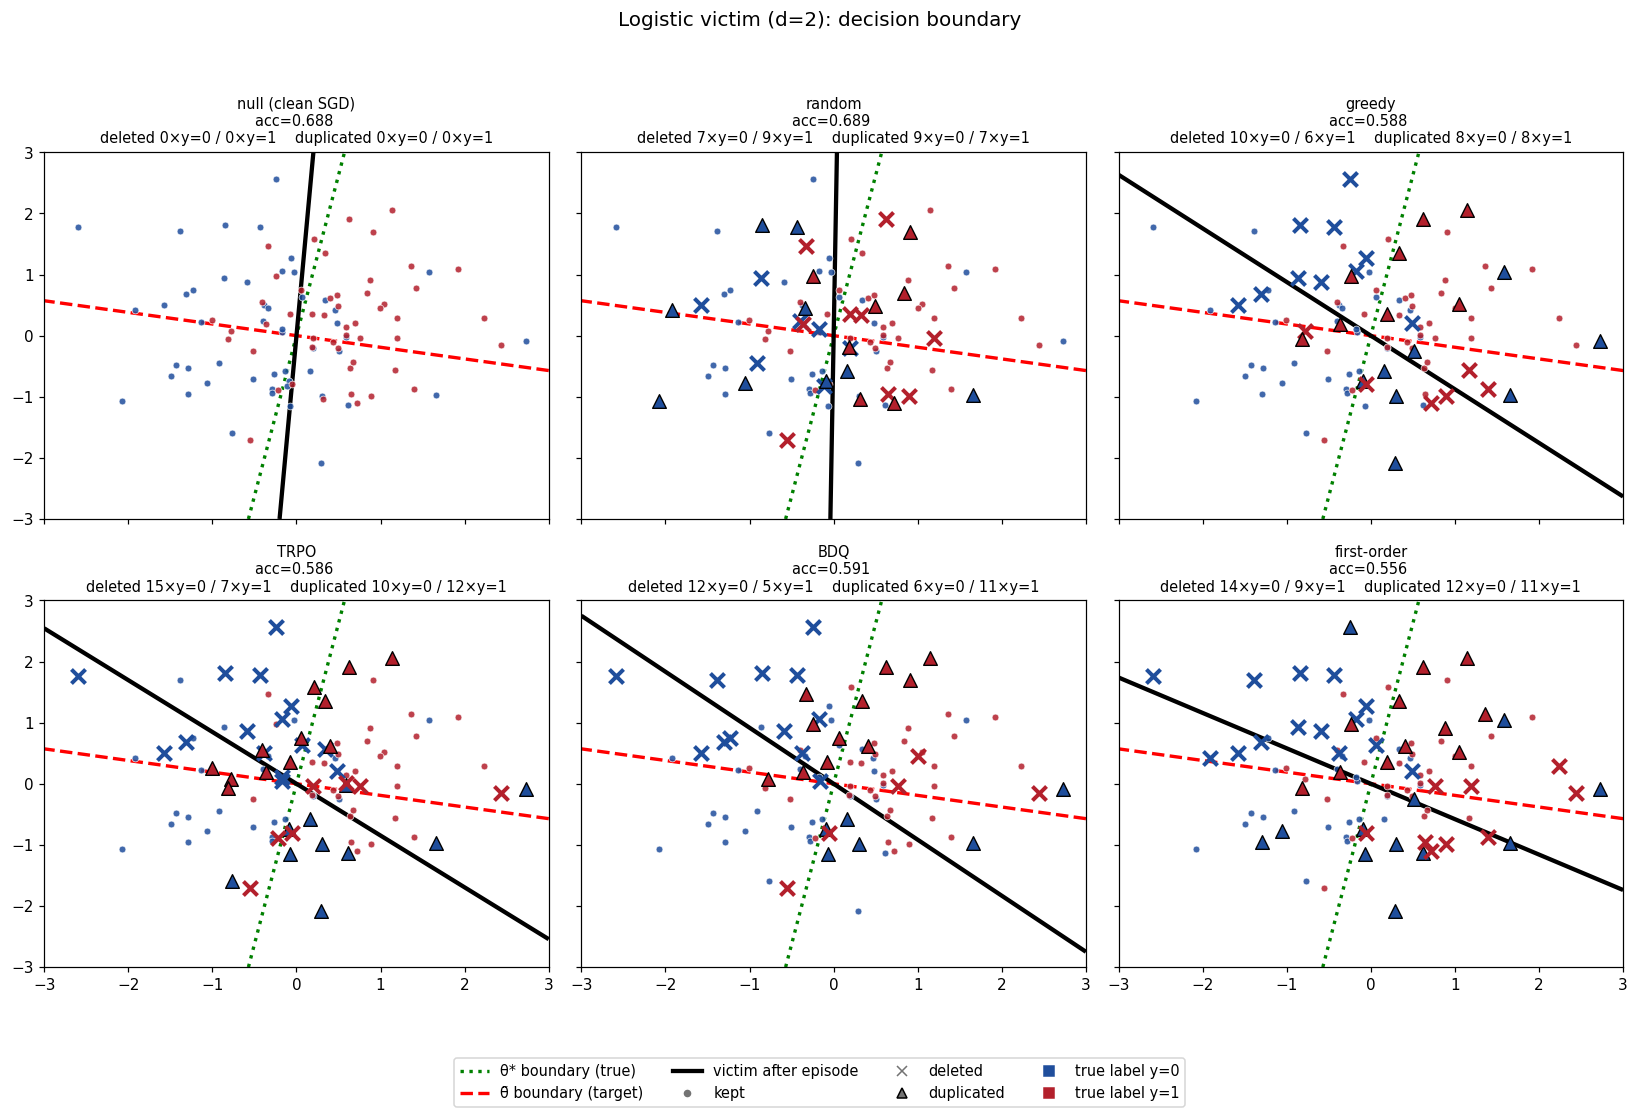

policy                  acc    ∠θ̃  del y=0  del y=1  dup y=0  dup y=1
null (clean SGD)      0.688    83°        0        0        0        0
random                0.689    80°        7        9        9        7
greedy                0.588    30°       10        6        8        8
TRPO                  0.586    30°       15        7       10       12
BDQ                   0.591    32°       12        5        6       11
first-order           0.556    19°       14        9       12       11

reference: ∠(θ*, θ̃) = 90°  (null stays near θ*, a successful attack drives the angle to θ̃ toward 0°)
Single episode, single seed, rotated target — illustrative, not a benchmark; the quantitative comparison is §1.


In [9]:
INCLUDE_MODEL_FREE_BOUNDARY = True     # BDQ ≈ 3.5 min, TRPO ≈ 1 min; False = skip both

E2 = replace(ECFG, d=2)
C2 = replace(CFG, K_iters=20)
torch.manual_seed(0)
env2 = Environment(E2, C2)

# See the note above: rotate the target so the attack is visible as a rotation.
_R = torch.tensor([[0., -1.], [1., 0.]])
env2.theta_target = (_R @ env2.stream.theta_star) / env2.stream.theta_star.norm() * 1.035

V2 = train_fvi(env2, C2, seed=0, verbose=False, best_checkpoint=True,
               eval_episodes=100, eval_seed=EVAL_SEED)

policies = {
    "null (clean SGD)": NullAgent(),
    "random": RandomAgent(torch.Generator().manual_seed(2), C2.balance, C2.B, C2.L),
    "greedy": GreedyAgent(env2.victim, env2.theta_target, C2, mode="greedy"),
}
if INCLUDE_MODEL_FREE_BOUNDARY:
    from bdq import train_bdq, BDQAgent
    from trpo import train_trpo, TRPOAgent
    torch.manual_seed(0)
    Q2 = train_bdq(env2, C2, seed=0, verbose=False, best_checkpoint=True,
                   eval_episodes=100, eval_seed=EVAL_SEED)
    torch.manual_seed(0)
    P2 = train_trpo(env2, replace(C2, K_iters=50), seed=0, verbose=False,
                    best_checkpoint=True, eval_episodes=100, eval_seed=EVAL_SEED)
    policies["TRPO"] = TRPOAgent(P2, env2, C2, torch.Generator().manual_seed(1))
    policies["BDQ"] = BDQAgent(Q2, env2, C2, torch.Generator().manual_seed(1))
policies[TIER_NAME[C2.select_mode]] = MethodAgent(V2, env2.victim, env2.theta_target, C2,
                                        torch.Generator().manual_seed(1))

rng = torch.Generator().manual_seed(3)
batches = [env2.stream.sample_batch(env2.m, rng) for _ in range(env2.T)]   # shared stream


def run_on(agent):
    th = env2.theta_0.clone()
    xs, ys, acts = [], [], []
    for t, z in enumerate(batches):
        a = agent.act(th, z, t)
        xs.append(z[0]); ys.append(z[1]); acts.append(a)
        th = env2.victim.update(th, z, a).detach()
    return th, torch.cat(xs).numpy(), torch.cat(ys).numpy(), torch.cat(acts).numpy()


def angle(u, v):
    c = float(u @ v / (u.norm() * v.norm() + 1e-12))
    return float(np.degrees(np.arccos(np.clip(c, -1, 1))))


star, targ = env2.stream.theta_star, env2.theta_target
gg = torch.linspace(-3, 3, 220)
XX, YY = torch.meshgrid(gg, gg, indexing="ij")
grid = torch.stack([XX.reshape(-1), YY.reshape(-1)], -1)

def draw_boundary(ax, th, color, ls, lw=2.2):
    ax.contour(XX.numpy(), YY.numpy(), (grid @ th).reshape(220, 220).numpy(),
               levels=[0], colors=color, linestyles=ls, linewidths=lw)

ncols = 3
nrows = (len(policies) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 5.1 * nrows),
                         sharex=True, sharey=True, squeeze=False)
CLS = {0.0: "#1f4e9c", 1.0: "#b3202c"}          # class 0 = blue, class 1 = red
rows = []
for ax, (name, ag) in zip(axes.flat, policies.items()):
    th, X, Y, A = run_on(ag)
    for lab in (0.0, 1.0):
        c, sel = CLS[lab], Y == lab
        ax.scatter(X[sel & (A == 1), 0], X[sel & (A == 1), 1], s=20, c=c,
                   alpha=.85, edgecolors="white", linewidths=.5, zorder=3)
        ax.scatter(X[sel & (A == 0), 0], X[sel & (A == 0), 1], s=85, c=c,
                   marker="x", linewidths=2.6, zorder=4)
        ax.scatter(X[sel & (A == 2), 0], X[sel & (A == 2), 1], s=80, c=c,
                   marker="^", edgecolors="black", linewidths=.9, zorder=4)
    draw_boundary(ax, star, "g", ":")
    draw_boundary(ax, targ, "red", "--")
    draw_boundary(ax, th, "k", "-", 2.8)
    acc = accuracy(env2, th)
    d0 = int(((A == 0) & (Y == 0)).sum()); d1 = int(((A == 0) & (Y == 1)).sum())
    u0 = int(((A == 2) & (Y == 0)).sum()); u1 = int(((A == 2) & (Y == 1)).sum())
    rows.append((name, acc, angle(th, targ), d0, d1, u0, u1))
    ax.set_title(f"{name}\nacc={acc:.3f} \n"
                 f"deleted {d0}×y=0 / {d1}×y=1    duplicated {u0}×y=0 / {u1}×y=1",
                 fontsize=9.5)
    ax.set_xlim(-3, 3); ax.set_ylim(-3, 3)
for ax in list(axes.flat)[len(policies):]:
    ax.axis("off")

from matplotlib.lines import Line2D
fig.legend(handles=[
    Line2D([0], [0], color="g", ls=":", lw=2.2, label="θ* boundary (true)"),
    Line2D([0], [0], color="red", ls="--", lw=2.2, label="θ̃ boundary (target)"),
    Line2D([0], [0], color="k", ls="-", lw=2.8, label="victim after episode"),
    Line2D([0], [0], marker="o", color="0.45", ls="None", mec="w", label="kept"),
    Line2D([0], [0], marker="x", color="0.45", ls="None", label="deleted"),
    Line2D([0], [0], marker="^", color="0.45", ls="None", mec="k", label="duplicated"),
    Line2D([0], [0], marker="s", color=CLS[0.0], ls="None", label="true label y=0"),
    Line2D([0], [0], marker="s", color=CLS[1.0], ls="None", label="true label y=1")],
    loc="lower center", ncol=4, fontsize=9.5)
fig.suptitle("Logistic victim (d=2): decision boundary",
             fontsize=13)
fig.tight_layout(rect=(0, 0.09, 1, 0.95)); plt.show()

print(f"{'policy':20}{'acc':>7}{'∠θ̃':>7}{'del y=0':>9}{'del y=1':>9}"
      f"{'dup y=0':>9}{'dup y=1':>9}")
for r in rows:
    print(f"{r[0]:20}{r[1]:>7.3f}{r[2]:>6.0f}°{r[3]:>9d}{r[4]:>9d}{r[5]:>9d}{r[6]:>9d}")
print(f"\nreference: ∠(θ*, θ̃) = {angle(star, targ):.0f}°  "
      f"(null stays near θ*, a successful attack drives the angle to θ̃ toward 0°)")
print("Single episode, single seed, rotated target — illustrative, not a benchmark; "
      "the quantitative comparison is §1.")

## 4. Interaction diagnostics

How much does the quadratic term matter on this task? If `|½aᵀBa| / |aᵀα|` is small, `greedy`
is near-optimal and the interaction can safely be dropped.

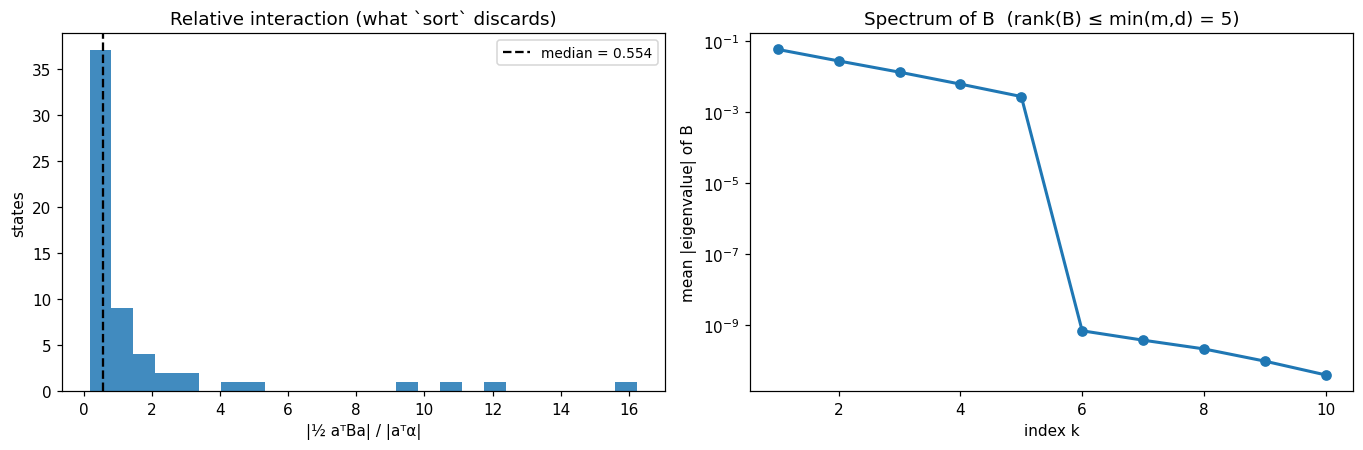

relative interaction: median 0.5541  mean 1.6744


In [7]:
alpha_rel, spec = [], []
rng = torch.Generator().manual_seed(EVAL_SEED)
theta = env.theta_0.clone()
for i in range(60):
    t = i % env.T
    if t == 0:
        theta = env.theta_0.clone()
    z = env.stream.sample_batch(env.m, rng)
    alpha, Gamma = scores_and_interaction(V, theta, z, t, env.victim, env.theta_target,
                                      CFG.lam, need_Gamma=True, use_hessian=CFG.use_hessian_in_B)
    a = res["first-order"]["agent"].act(theta, z, t)
    lin = float(a @ alpha)
    alpha_rel.append(abs(float(0.5 * a @ B @ a)) / (abs(lin) + 1e-12))
    spec.append(np.sort(np.abs(np.linalg.eigvalsh(0.5 * (B + B.T).numpy())))[::-1])
    theta = env.victim.update(theta, z, a).detach()

spec = np.array(spec)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12.5, 4.2))
a1.hist(alpha_rel, bins=25, color="C0", alpha=0.85)
a1.axvline(np.median(alpha_rel), color="k", ls="--", lw=1.5,
           label=f"median = {np.median(alpha_rel):.3f}")
a1.set_xlabel("|½ aᵀBa| / |aᵀα|"); a1.set_ylabel("states")
a1.set_title("Relative interaction (what `sort` discards)"); a1.legend(fontsize=9)

a2.semilogy(np.arange(1, spec.shape[1] + 1), spec.mean(0), "o-", color="C0", lw=2)
a2.set_xlabel("index k"); a2.set_ylabel("mean |eigenvalue| of B")
a2.set_title(f"Spectrum of B  (rank(B) ≤ min(m,d) = {min(ECFG.m, env.d)})")
plt.tight_layout(); plt.show()
print(f"relative interaction: median {np.median(alpha_rel):.4f}  mean {np.mean(alpha_rel):.4f}")

## 5. Why `eta` and `c_edit` had to be retuned

The logistic residual is bounded, so `|φ|` is ~5× smaller than in least squares. At the
regression defaults the attack is invisible; too large an `eta` makes the victim unstable.
This sweep is what set the configuration above.

eta=0.2  c_edit=0.1   null=  4.550 greedy=  4.550 first-order=  4.481  (0.985 x null)
eta=0.5  c_edit=0.1   null=  4.576 greedy=  4.575 first-order=  4.014  (0.877 x null)
eta=1.0  c_edit=0.1   null=  5.899 greedy=  5.513 first-order=  4.614  (0.782 x null)
eta=1.5  c_edit=0.1   null=  7.793 greedy=  6.929 first-order=  6.125  (0.786 x null)
eta=2.0  c_edit=0.1   null= 10.031 greedy= 10.300 first-order= 10.250  (1.022 x null)
eta=0.2  c_edit=0.02  null=  4.550 greedy=  4.413 first-order=  3.388  (0.745 x null)
eta=0.5  c_edit=0.02  null=  4.576 greedy=  2.813 first-order=  2.226  (0.486 x null)
eta=1.0  c_edit=0.02  null=  5.899 greedy=  3.114 first-order=  2.661  (0.451 x null)
eta=1.5  c_edit=0.02  null=  7.793 greedy=  5.869 first-order=  4.871  (0.625 x null)
eta=2.0  c_edit=0.02  null= 10.031 greedy= 10.984 first-order= 10.221  (1.019 x null)


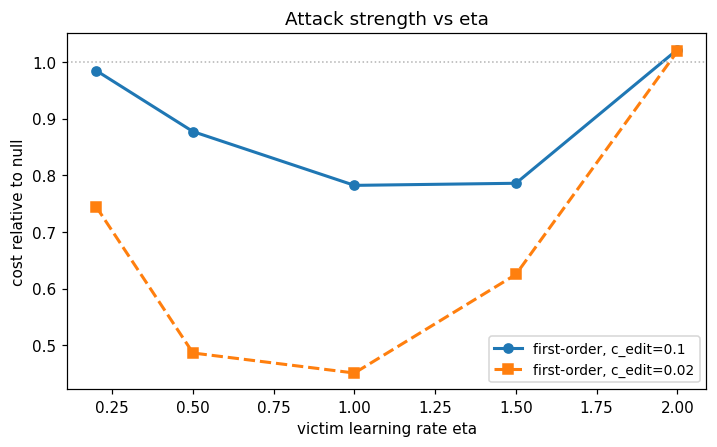

In [11]:
rows = []
for eta, ce in [(0.2, 0.1), (0.5, 0.1), (1.0, 0.1), (1.5, 0.1), (2.0, 0.1), (0.2, 0.02), (0.5, 0.02), (1.0, 0.02), (1.5, 0.02), (2.0, 0.02)]:
    c = replace(CFG, c_edit=ce)
    e = replace(ECFG, eta=eta)
    torch.manual_seed(0)
    en = Environment(e, c)
    Vs = train_fvi(en, c, seed=0, verbose=False, best_checkpoint=True,
                   eval_episodes=EVAL_EPISODES, eval_seed=EVAL_SEED)
    ag = MethodAgent(Vs, en.victim, en.theta_target, c, torch.Generator().manual_seed(1))
    gr = GreedyAgent(en.victim, en.theta_target, c, mode="greedy")
    n_ = evaluate(en, NullAgent(), torch.Generator().manual_seed(EVAL_SEED), EVAL_EPISODES)
    g_ = evaluate(en, gr, torch.Generator().manual_seed(EVAL_SEED), EVAL_EPISODES)
    m_ = evaluate(en, ag, torch.Generator().manual_seed(EVAL_SEED), EVAL_EPISODES)
    rows.append((eta, ce, n_, g_, m_))
    print(f"eta={eta:<4} c_edit={ce:<5} null={n_:7.3f} greedy={g_:7.3f} "
          f"{TIER_NAME[CFG.select_mode]}={m_:7.3f}  ({m_/n_:.3f} x null)")

r = np.array(rows)
plt.figure(figsize=(7.5, 4.2))
for ce, mk in [(0.1, "o-"), (0.02, "s--")]:
    s = r[r[:, 1] == ce]
    if len(s):
        plt.plot(s[:, 0], s[:, 4] / s[:, 2], mk, lw=2, label=f"{TIER_NAME[CFG.select_mode]}, c_edit={ce}")
plt.axhline(1.0, color="0.7", ls=":", lw=1)
plt.xlabel("victim learning rate eta"); plt.ylabel("cost relative to null")
plt.title("Attack strength vs eta"); plt.legend(fontsize=9); plt.show()

## 6. Sensitivity analysis  *(heavy — all flags default to `False`)*

The same sweeps as §7 of [experiment_linear.ipynb](experiment_linear.ipynb), re-run against
the **logistic** victim. Same fairness protocol as §1: every learner is retrained at every
point, all policies are scored on the identical held-out episodes, feasibility asserted
throughout. Axis labels and titles are kept identical to the linear notebook so the two
sets of figures can be read side by side.

| § | axis | why it matters | points × seeds | ≈ runtime |
|---|---|---|---|---|
| 6a | `c_edit` | **the** axis — `c_edit` is what demands per-point credit resolution | 6 × 1 | ~1.1 h |
| 6b | `m` | separates action-space growth from edit economics | 5 × 2 × 1 | ~1.8 h |
| 6c | `T` | isolates what the learned cost-to-go buys over myopic greedy | 6 × 1 | ~1.1 h |
| 6d | linearity violation | converts the scope caveat into a measured bound | 10 × 1 | ~1.8 h |

**What differs from the linear notebook.** The logistic residual is bounded in `(-1,1)`, so
`|φ|` is ~5× smaller and `eta=1.0`, `c_edit=0.02` (§5). Every sweep is therefore recentred
on **`c_edit=0.02`, not `0.1`** — the `c_edit/|α|` economics, not the raw number, is what
transfers.

In [ ]:
# --- shared sweep machinery (mirrors experiment_linear.ipynb §7) -------------
from config import TIER_MODE
from bdq import train_bdq, BDQAgent
from trpo import train_trpo, TRPOAgent

RUN_CEDIT     = False    # 6a  ~1.1 h
RUN_M_SENS    = False    # 6b  ~1.8 h
RUN_T_SENS    = False    # 6c  ~1.1 h
RUN_VIOLATION = False    # 6d  ~1.8 h

SEEDS          = (0,)                # logistic §1 is single-seed; add more if affordable
K_COMPARE      = CFG.K_iters         # matched budget for ALL learners
SWEEP_LEARNERS = ["first-order", "BDQ", "TRPO"]               # retrained per point
SWEEP_FREE     = ["null", "greedy"]                           # training-free
COLORS = {"null": "#5b5b5b", "greedy": "#eb6834", "TRPO": "#4a3aa7",
          "BDQ": "#e34948", "first-order": "#2a78d6", "exact": "#e87ba4"}
# ours (any selector tier) shares one marker; every baseline gets its own
MARKERS = {"null": "D", "greedy": "s", "TRPO": "^", "BDQ": "X",
           "first-order": "o", "exact": "o"}


def sweep_behaviour(env, agent, n_episodes=40, seed=EVAL_SEED):
    """(edits per step, all-feasible?).  Local copy: §1's `behaviour` returns
    (edits, gap) and asserts internally, which is the wrong shape for the sweep."""
    rng = torch.Generator().manual_seed(seed)
    edits, steps, ok = 0.0, 0, True
    for _ in range(n_episodes):
        theta = env.theta_0.clone()
        for t in range(env.T):
            z = env.stream.sample_batch(env.m, rng)
            a = agent.act(theta, z, t)
            ok &= is_feasible(a, CFG.balance, CFG.B, CFG.L)
            edits += float(np.abs(a.numpy() - 1).sum())
            theta = env.victim.update(theta, z, a).detach()
            steps += 1
    return edits / steps, ok


def decision_latency_ms(env, agent, n=200, seed=1):
    """Mean wall-clock of one agent.act() call, in milliseconds."""
    rng = torch.Generator().manual_seed(seed)
    theta, z = env.theta_0.clone(), env.stream.sample_batch(env.m, rng)
    agent.act(theta, z, 0)                                    # warm-up
    t0 = time.perf_counter()
    for k in range(n):
        agent.act(theta, z, k % env.T)
    return (time.perf_counter() - t0) / n * 1e3


def build_agents(env, cfg, seed, learners=SWEEP_LEARNERS):
    """Train `learners` on this env/cfg; return {name: agent} incl. the free baselines."""
    ags = {"null": NullAgent(),
           "greedy": GreedyAgent(env.victim, env.theta_target,
                                 replace(cfg, select_mode="greedy"), mode="greedy")}
    for name in learners:
        torch.manual_seed(seed)                       # identical init across learners
        if name == "BDQ":
            net = train_bdq(env, cfg, seed=seed, verbose=False, best_checkpoint=True,
                            eval_episodes=EVAL_EPISODES, eval_seed=EVAL_SEED)
            ags[name] = BDQAgent(net, env, cfg, torch.Generator().manual_seed(seed + 1))
        elif name == "TRPO":
            cfg_t = replace(cfg, K_iters=max(cfg.K_iters, TRPO_ITERS))
            net = train_trpo(env, cfg_t, seed=seed, verbose=False, best_checkpoint=True,
                             eval_episodes=EVAL_EPISODES, eval_seed=EVAL_SEED)
            ags[name] = TRPOAgent(net, env, cfg_t, torch.Generator().manual_seed(seed + 1),
                                  deterministic=True)
        else:
            cfg_t = replace(cfg, select_mode=TIER_MODE[name])
            V_s = train_fvi(env, cfg_t, seed=seed, verbose=False, best_checkpoint=True,
                            eval_episodes=EVAL_EPISODES, eval_seed=EVAL_SEED)
            ags[name] = MethodAgent(V_s, env.victim, env.theta_target, cfg_t,
                                    torch.Generator().manual_seed(seed + 1))
    return ags


def sweep(values, make_cfgs, seeds=(0,), learners=SWEEP_LEARNERS, label="x",
          post_env=None, n_beh=40):
    """1-D sweep: retrain every learner at every point, score on the shared episodes.

    make_cfgs(v) -> (EnvConfig, MethodConfig) for axis value v.
    post_env(env, v) may mutate the freshly built Environment (used by 6d).
    Returns {name: {"cost", "cost_sd", "edits"}}, each a list over `values`.
    """
    names = SWEEP_FREE + list(learners)
    res = {n: {"cost": [], "cost_sd": [], "edits": []} for n in names}
    for v in values:
        ecfg_v, cfg_v = make_cfgs(v)
        per_c = {n: [] for n in names}
        per_e = {n: [] for n in names}
        for s in seeds:
            torch.manual_seed(s)
            env_v = Environment(ecfg_v, cfg_v)
            if post_env is not None:
                post_env(env_v, v)
            ags = build_agents(env_v, cfg_v, s, learners)
            for n in names:
                per_c[n].append(evaluate(env_v, ags[n],
                                torch.Generator().manual_seed(EVAL_SEED), EVAL_EPISODES))
                e_, ok = sweep_behaviour(env_v, ags[n], n_episodes=n_beh)
                assert ok, f"{n} emitted an infeasible action at {label}={v}"
                per_e[n].append(e_)
        for n in names:
            res[n]["cost"].append(float(np.mean(per_c[n])))
            res[n]["cost_sd"].append(float(np.std(per_c[n])))
            res[n]["edits"].append(float(np.mean(per_e[n])))
        print(f"  {label}={v}: " +
              "  ".join(f"{n}={res[n]['cost'][-1]:.2f}" for n in names), flush=True)
    return res


def plot_sweep(xs, res, xlabel, title, panel2="edits", xticks=None):
    """Left: cost/null. Right: edits/step ('edits') or planning premium ('premium')."""
    names = list(res)
    nul = np.array(res["null"]["cost"])
    fig, (p1, p2) = plt.subplots(1, 2, figsize=(12.5, 4.3))
    for n in names:
        p1.plot(xs, np.array(res[n]["cost"]) / nul, f"{MARKERS[n]}-", color=COLORS[n], lw=2, label=n)
    p1.axhline(1.0, color="0.7", ls=":", lw=1)
    p1.set_xlabel(xlabel); p1.set_ylabel("cost / null  (lower = stronger attack)")
    p1.set_title(title); p1.legend(fontsize=8)

    if panel2 == "premium":
        g = np.array(res["greedy"]["cost"])
        for n in ["first-order"]:
            if n in res:
                p2.plot(xs, (g - np.array(res[n]["cost"])) / g * 100, f"{MARKERS[n]}-",
                        color=COLORS[n], lw=2, label=f"{n} vs greedy")
        p2.axhline(0, color="k", lw=0.8)
        p2.set_ylabel("cost reduction vs greedy (%)")
        p2.set_title("Planning premium — what the learned V̂ buys")
    else:
        for n in names:
            if n != "null":
                p2.plot(xs, res[n]["edits"], f"{MARKERS[n]}-", color=COLORS[n], lw=2, label=n)
        p2.set_ylabel("mean points edited per step")
        p2.set_title("Willingness to pay for edits")
    p2.set_xlabel(xlabel); p2.legend(fontsize=8)
    for p in (p1, p2):
        if xticks is not None:
            p.set_xticks(xticks)
    plt.tight_layout(); plt.show()


print("sweep helpers ready — flags:",
      {"6a": RUN_CEDIT, "6b": RUN_M_SENS, "6c": RUN_T_SENS,
       "6d": RUN_VIOLATION})

### 6a. Edit price `c_edit` — the credit-resolution axis

Same hypothesis as the linear case: the methods order by how finely they attribute cost to
individual points — TRPO gets **one scalar** advantage for the whole joint action, BDQ gets
**per-branch** Q-values, ours gets a **per-point analytic `αᵢ`**. `c_edit` is the knob that
demands that discrimination, so each policy should fall off toward null at the price its
credit resolution can no longer resolve, in that order.

**Recentred for logistic.** The bounded residual makes `|α|` ~5× smaller, so the sweep runs
`0 → 0.08` around the tuned `c_edit=0.02` rather than `0 → 0.4` around `0.1`. What transfers
between the two notebooks is the ratio `c_edit/|α|`, not the raw price.

The §5 sweep already showed the attack is invisible at the regression defaults; this asks
the sharper question of *which method degrades first* as the price rises.

In [ ]:
CEDITS      = [0.0, 0.005, 0.01, 0.02, 0.04, 0.08]
CEDIT_SEEDS = SEEDS          # headline axis -- add seeds here if you can afford them

if RUN_CEDIT:
    res_ce = sweep(CEDITS,
                   lambda v: (ECFG, replace(CFG, c_edit=v, K_iters=K_COMPARE)),
                   seeds=CEDIT_SEEDS, label="c_edit")
    plot_sweep(CEDITS, res_ce, "edit price  c_edit",
               f"Attack strength vs edit price ({len(CEDIT_SEEDS)} seeds)",
               xticks=CEDITS)

    # where does each policy give up? first c_edit at which it is within 5% of null
    print("\ncollapse point (first c_edit with cost/null > 0.95):")
    nul = np.array(res_ce["null"]["cost"])
    for n in SWEEP_FREE[1:] + SWEEP_LEARNERS:
        r = np.array(res_ce[n]["cost"]) / nul
        hit = [c for c, v in zip(CEDITS, r) if v > 0.95]
        print(f"  {n:12} {'c_edit = ' + str(hit[0]) if hit else 'survives the whole sweep':30}"
              f"  (cost/null at c_edit={CEDITS[-1]}: {r[-1]:.3f})")
else:
    print("skipped — set RUN_CEDIT = True")

### 6b. Batch size `m` — action-space growth vs edit economics

Two confounded effects grow with `m`:

1. the joint action space grows as `3^m` — the reason BDQ exists;
2. per-point influence shrinks as `φᵢ ∝ 1/m` (the victim averages the batch), so at
   **fixed** `c_edit` every edit becomes less profitable and *all* policies drift to null.

Effect 2 is economics, not combinatorics, and it will masquerade as "the method breaks at
large `m`" if you only read the left panel. Holding `c_edit·m` constant (right panel)
neutralises it, so the only thing left changing is the size of the action space.

Degradation that survives on the **right** is a genuine scaling limit; degradation that
appears only on the **left** is the edit price rising in disguise.

In [ ]:
MS_SENS = [4, 6, 8, 10, 14]

if RUN_M_SENS:
    res_m = {}
    for scaled in (False, True):
        tag = "c_edit*m held constant" if scaled else "c_edit fixed"
        print(f"[{tag}]")
        res_m[scaled] = sweep(
            MS_SENS,
            lambda m, sc=scaled: (replace(ECFG, m=m),
                                  replace(CFG, K_iters=K_COMPARE,
                                          c_edit=CFG.c_edit * ECFG.m / m if sc
                                          else CFG.c_edit)),
            seeds=(SEEDS[0],), label="m")

    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3), sharey=True)
    for ax, scaled, ttl in [(axes[0], False, f"c_edit fixed at {CFG.c_edit}"),
                            (axes[1], True, f"c_edit·m held at {CFG.c_edit*ECFG.m:.2f}")]:
        r = res_m[scaled]
        nul = np.array(r["null"]["cost"])
        for n in r:
            ax.plot(MS_SENS, np.array(r[n]["cost"]) / nul, f"{MARKERS[n]}-",
                    color=COLORS[n], lw=2, label=n)
        ax.axhline(1.0, color="0.7", ls=":", lw=1)
        ax.set_xlabel("batch size m   (action space = 3^m)")
        ax.set_xticks(MS_SENS); ax.set_title(ttl); ax.legend(fontsize=8)
    axes[0].set_ylabel("cost / null")
    fig.suptitle("Scaling in m", y=1.02)
    plt.tight_layout(); plt.show()

    print(f"\n{'m':>4}{'3^m':>12}   " +
          "".join(f"{n:>14}" for n in ["first-order", "BDQ"]))
    for i, m in enumerate(MS_SENS):
        f_ = res_m[True]["first-order"]["cost"][i] / res_m[True]["null"]["cost"][i]
        b_ = res_m[True]["BDQ"]["cost"][i] / res_m[True]["null"]["cost"][i]
        print(f"{m:>4}{3**m:>12,}   {f_:>14.3f}{b_:>14.3f}   (c_edit·m fixed)")
else:
    print("skipped — set RUN_M_SENS = True")

### 6c. Horizon `T` — what the learned cost-to-go buys

`greedy` **is** the myopic special case of our own decomposition (`V̂ ≡ 0`, see
[agents.py](agents.py) — `αᵢ = λ⟨e, φᵢ⟩`, `B = λΦΦᵀ`). It runs the identical selector with
the identical `c_edit`, so the gap between `first-order` and `greedy` isolates one thing:
the value of the learned cost-to-go.

**Built-in sanity check.** At `T=1` there is no future — `V̂(θ, t+1)` is evaluated at
`t+1 = T`, which the value net defines as `0` — so `α` reduces exactly to greedy's and the
two policies must coincide. The cell asserts it. This is model-independent: it tests the
time indexing in `decomposition.py`, not anything about logistic regression, so it should
pass here exactly as it does in the linear notebook.

In [ ]:
TS_SENS = [1, 2, 4, 6, 10, 14]

if RUN_T_SENS:
    res_T = sweep(TS_SENS,
                  lambda T: (replace(ECFG, T=T), replace(CFG, K_iters=K_COMPARE)),
                  seeds=(SEEDS[0],), label="T")
    plot_sweep(TS_SENS, res_T, "horizon T", "Attack strength vs planning horizon",
               panel2="premium", xticks=TS_SENS)

    g1, f1 = res_T["greedy"]["cost"][0], res_T["first-order"]["cost"][0]
    print(f"\nT=1 sanity check: greedy={g1:.4f}  first-order={f1:.4f}  "
          f"|diff|={abs(g1-f1):.2e}")
    assert abs(g1 - f1) < 1e-6 * max(1.0, abs(g1)), \
        "at T=1 the method must reduce to greedy (V̂(·,T)=0) -- check the t+1 indexing"

    g = np.array(res_T["greedy"]["cost"])
    prem = (g - np.array(res_T["first-order"]["cost"])) / g * 100
    print("planning premium vs greedy:  " +
          "  ".join(f"T={T}: {p:+.1f}%" for T, p in zip(TS_SENS, prem)))
else:
    print("skipped — set RUN_T_SENS = True")

### 6d. Graded violation of action-linearity — the scope of the method

The advantage is bought with a modelling assumption, `θ_{t+1} = θ_t + Σ aᵢ φᵢ`. §0 argues
that assumption survives the move from least squares to logistic *unchanged*, because both
have gradient `resid_i · x_i` and only the residual differs. That is a claim about the
**exact** case; this section asks how much mismatch the advantage tolerates.

Two knobs, each attacking a different half of *"sum-structured loss + exactly one step"*:

| knob | what it breaks | exact at |
|---|---|---|
| **global grad-norm clip `τ`** | sum structure — the clip applies to `Σ aᵢ∇ℓᵢ` *after* aggregation, so the update is no longer separable | `τ = ∞` |
| **inner SGD steps `n`** | "exactly one step" — steps 2…`n` re-linearise at a `θ` the attacker never modelled | `n = 1` |

Per-sample clipping is deliberately not used: it is still exactly affine in `a`, so it
violates nothing. It is the *aggregate* clip — what `torch.nn.utils.clip_grad_norm_` does —
that breaks separability.

**Logistic-specific note.** The residual is already bounded in `(-1,1)`, so the raw update
norm is small and less variable than in the regression case. Expect the clip to bite later
(at smaller `ρ`) but the multi-step knob to bite *harder*: `σ` saturation means re-linearising
at a new `θ` can change the gradient direction, not just its length.

**The wrapper overrides `update` (the true dynamics) but leaves `phi_batch` (the attacker's
model) linear.** Every learner trains on the true dynamics; only our `α`/`B` carry the
assumption — BDQ and TRPO assumed nothing and are the control.

**How to read it.** A clipped or multi-step victim is a genuinely *different control
problem*: `null` moves too (hence the `cost/null` y-axis) and the baselines are **not**
guaranteed flat. Read the **gap between our curve and the best baseline at each violation
level**, not our own degradation against the exact case.

In [ ]:
class ClipVictim:
    """Clips the AGGREGATE update to norm tau -- breaks separability in `a`.

    phi_batch (the attacker's model) is left linear on purpose: the mismatch between
    `update` and `theta + a @ Phi` IS the experiment.
    """

    def __init__(self, base, tau):
        self.base, self.tau = base, tau
        self.eta, self.task = base.eta, getattr(base, "task", "logistic")

    def residual(self, theta, z):
        return self.base.residual(theta, z)

    def phi_batch(self, theta, z):
        return self.base.phi_batch(theta, z)

    def update(self, theta, z, a):
        step = a @ self.base.phi_batch(theta, z)
        nrm = step.norm()
        if self.tau is not None and float(nrm) > self.tau:
            step = step * (self.tau / nrm)
        return theta + step


class MultiStepVictim:
    """n SGD steps on the same reweighted batch -- breaks 'exactly one step'.

    n=1 is exactly the base victim, so the sweep has a clean exact anchor.
    """

    def __init__(self, base, n_steps):
        self.base, self.n_steps = base, n_steps
        self.eta, self.task = base.eta, getattr(base, "task", "logistic")

    def residual(self, theta, z):
        return self.base.residual(theta, z)

    def phi_batch(self, theta, z):
        return self.base.phi_batch(theta, z)     # attacker still assumes ONE step

    def update(self, theta, z, a):
        th = theta
        for _ in range(self.n_steps):
            th = th + a @ self.base.phi_batch(th, z)   # re-linearised at the new theta
        return th


def linearity_error(env, agent, n_states=60, seed=EVAL_SEED):
    """Mean ‖update(θ,z,a) − (θ + Σ aᵢφᵢ)‖ / ‖Σ aᵢφᵢ‖ over states the policy visits."""
    rng = torch.Generator().manual_seed(seed)
    errs, theta = [], env.theta_0.clone()
    for i in range(n_states):
        if i % env.T == 0:
            theta = env.theta_0.clone()
        z = env.stream.sample_batch(env.m, rng)
        a = agent.act(theta, z, i % env.T)
        pred = theta + a @ env.victim.phi_batch(theta, z)
        true = env.victim.update(theta, z, a).detach()
        errs.append(float((true - pred).norm() / ((pred - theta).norm() + 1e-12)))
        theta = true
    return float(np.mean(errs))


RHOS    = [None, 1.0, 0.6, 0.4, 0.25, 0.12]   # clip threshold / typical step norm
NSTEPS  = [1, 2, 3, 4]

if RUN_VIOLATION:
    # reference step norm: median ‖Σ aᵢφᵢ‖ under the unclipped greedy policy
    torch.manual_seed(SEEDS[0])
    _env0 = Environment(ECFG, replace(CFG, K_iters=K_COMPARE))
    _g0 = GreedyAgent(_env0.victim, _env0.theta_target, CFG, mode="greedy")
    _rng, _norms, _th = torch.Generator().manual_seed(EVAL_SEED), [], _env0.theta_0.clone()
    for i in range(200):
        if i % _env0.T == 0:
            _th = _env0.theta_0.clone()
        _z = _env0.stream.sample_batch(_env0.m, _rng)
        _a = _g0.act(_th, _z, i % _env0.T)
        _norms.append(float((_a @ _env0.victim.phi_batch(_th, _z)).norm()))
        _th = _env0.victim.update(_th, _z, _a).detach()
    STEP0 = float(np.median(_norms))
    print(f"typical unclipped step norm = {STEP0:.4f}  -> tau = rho * {STEP0:.4f}\n")

    print("[aggregate gradient clipping]")
    res_clip = sweep(RHOS,
                     lambda r: (ECFG, replace(CFG, K_iters=K_COMPARE)),
                     seeds=(SEEDS[0],), label="rho",
                     post_env=lambda env, r: setattr(
                         env, "victim", ClipVictim(env.victim,
                                                   None if r is None else r * STEP0)))

    print("[multiple inner SGD steps]")
    res_step = sweep(NSTEPS,
                     lambda n: (ECFG, replace(CFG, K_iters=K_COMPARE)),
                     seeds=(SEEDS[0],), label="n_steps",
                     post_env=lambda env, n: setattr(
                         env, "victim", MultiStepVictim(env.victim, n)))

    # measured violation at each point (uses the greedy policy: no training needed)
    def violation_curve(values, wrap):
        out = []
        for v in values:
            torch.manual_seed(SEEDS[0])
            e = Environment(ECFG, replace(CFG, K_iters=K_COMPARE))
            e.victim = wrap(e.victim, v)
            out.append(linearity_error(
                e, GreedyAgent(e.victim, e.theta_target, CFG, mode="greedy")) * 100)
        return out

    vio_clip = violation_curve(RHOS, lambda vic, r: ClipVictim(vic, None if r is None
                                                               else r * STEP0))
    vio_step = violation_curve(NSTEPS, MultiStepVictim)

    fig, (c1, c2) = plt.subplots(1, 2, figsize=(12.5, 4.3), sharey=True)
    for ax, xs, res_, xlab, ttl, inv in [
            (c1, range(len(RHOS)), res_clip,
             "clip threshold  τ / typical step", "Aggregate gradient clipping", True),
            (c2, NSTEPS, res_step,
             "inner SGD steps per round", "Multiple inner steps", False)]:
        nul = np.array(res_["null"]["cost"])
        for n in res_:
            ax.plot(list(xs), np.array(res_[n]["cost"]) / nul, f"{MARKERS[n]}-",
                    color=COLORS[n], lw=2, label=n)
        ax.axhline(1.0, color="0.7", ls=":", lw=1)
        ax.set_xlabel(xlab); ax.set_title(ttl); ax.legend(fontsize=8)
        if inv:
            ax.set_xticks(list(xs))
            ax.set_xticklabels(["exact" if r is None else f"{r:g}" for r in RHOS])
    c1.set_ylabel("cost / null")
    fig.suptitle("How much action-linearity violation does the advantage survive?", y=1.02)
    plt.tight_layout(); plt.show()

    print(f"\n{'setting':>22}{'violation':>12}{'first-order':>14}{'BDQ':>10}{'TRPO':>10}")
    for lbl, res_, vio, vals in [("clip rho", res_clip, vio_clip, RHOS),
                                 ("inner steps", res_step, vio_step, NSTEPS)]:
        nul = np.array(res_["null"]["cost"])
        for i, v in enumerate(vals):
            tag = f"{lbl}={'exact' if v is None else v}"
            print(f"{tag:>22}{vio[i]:>11.1f}%"
                  f"{res_['first-order']['cost'][i]/nul[i]:>14.3f}"
                  f"{res_['BDQ']['cost'][i]/nul[i]:>10.3f}"
                  f"{res_['TRPO']['cost'][i]/nul[i]:>10.3f}")
    print("\nquote the violation column, not rho: it is the transferable number.")
else:
    print("skipped — set RUN_VIOLATION = True")

### Takeaways

1. **The method transfers with a one-line change** (`Victim.residual`) because
   action-linearity is a property of *per-point SGD*, not of least squares.
2. **Scale must be retuned.** Bounded logistic residuals shrink `|φ|` ~5×, which by the
   same `c_edit/|α|` economics makes a fixed edit price ~5× more punitive.
3. **Damage is interpretable** for a classifier: accuracy drops and the decision boundary
   visibly rotates toward `θ̃`.
4. **Margins are smaller than in regression.** The method still wins, but by less. The
   obvious explanation — bounded residuals compressing the `α` spectrum — was tested and
   **does not hold** (dispersion 1.29 vs 1.40, essentially equal), so the cause is still
   open. Candidates: σ-saturation capping every attacker, or a harder value-learning
   problem. Worth resolving before publishing a logistic headline number.